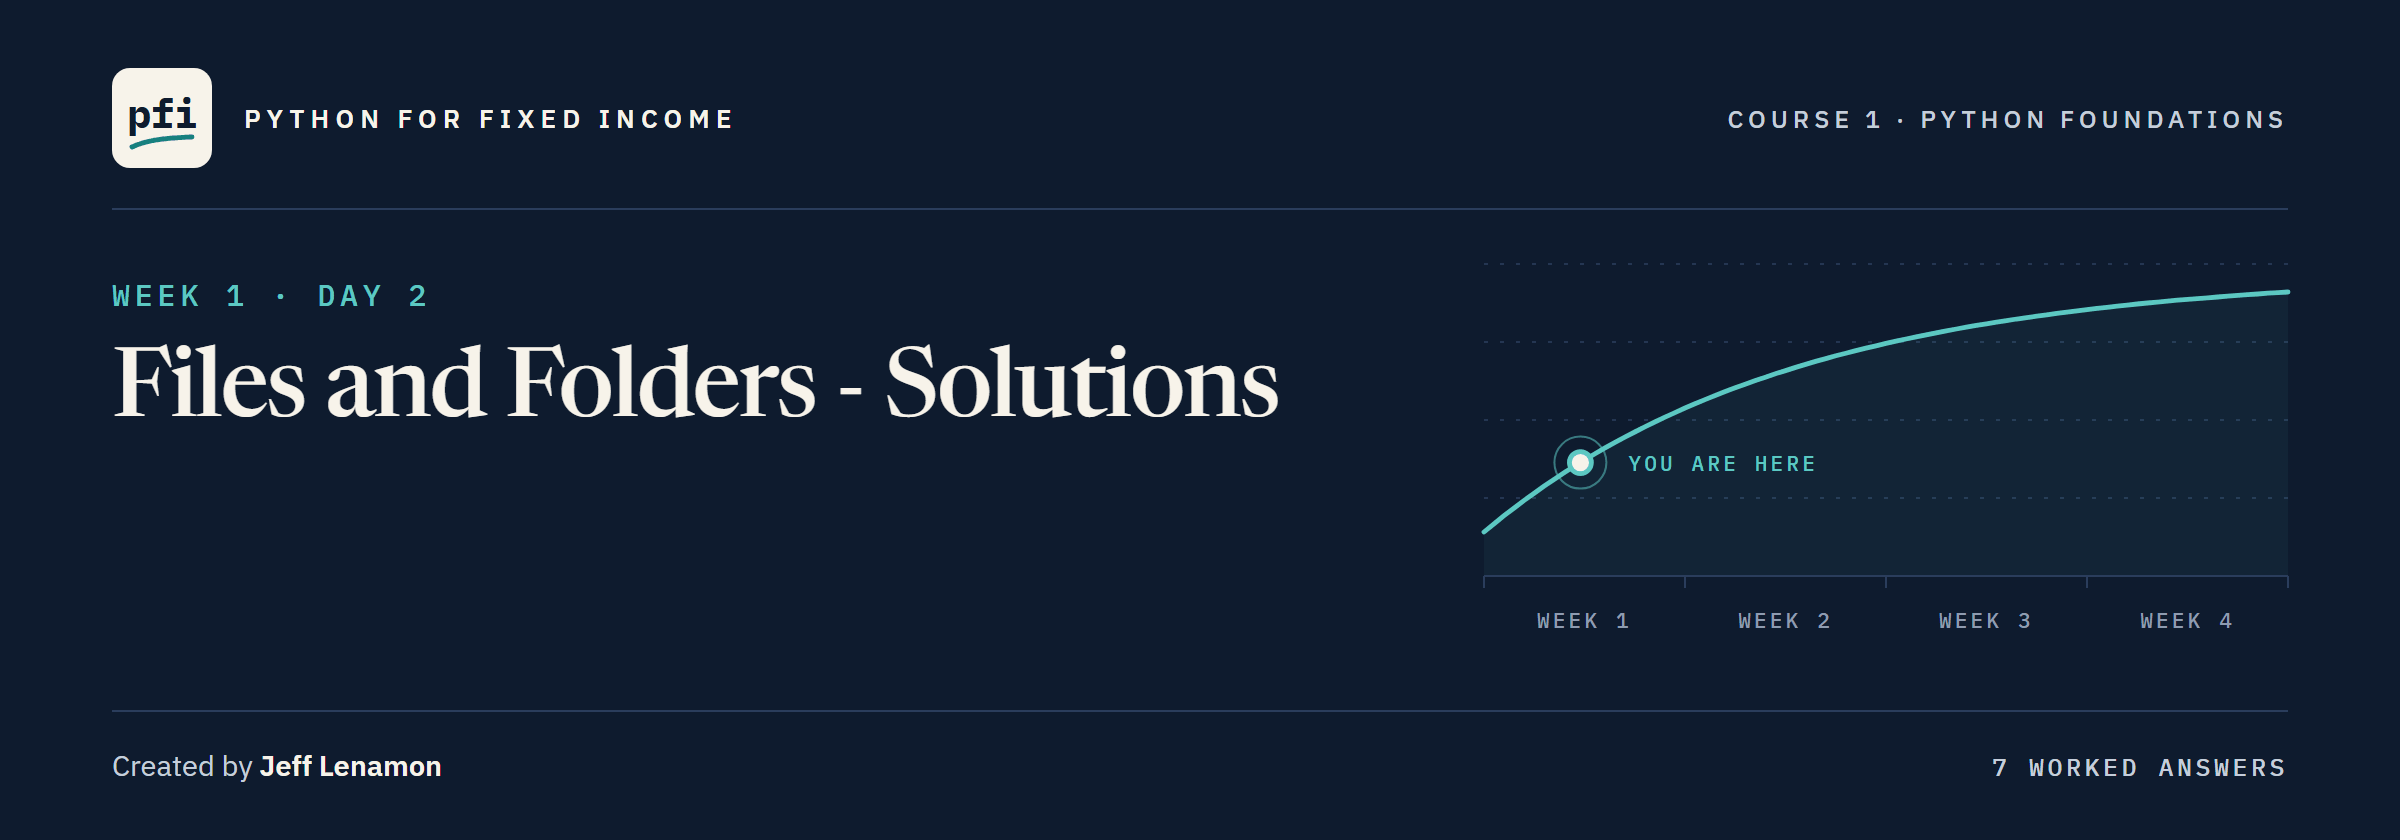

# Files and Folders - Solutions

Week 1, Day 2. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week1/day2/02_files_and_folders_solutions.ipynb)

## Exercises

A second desk bought three bonds today.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Face bought</th><th align="left">Price</th></tr>
<tr><td align="left">TRNW</td><td align="left">2,000,000</td><td align="left">96.25</td></tr>
<tr><td align="left">OSMC</td><td align="left">1,250,000</td><td align="left">100.00</td></tr>
<tr><td align="left">CLDB</td><td align="left">500,000</td><td align="left">104.50</td></tr>
</table>
<br clear="left">

Run the next cell first: it defines `check` and clears earlier attempts.

In [1]:
def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
    elif answer == expected:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)

import os
import shutil
# remove anything left over from an earlier attempt
for folder in ['blotter', 'trade_blotter']:
    shutil.rmtree(folder, ignore_errors=True)
if os.path.exists('ai_holdings.csv'):
    os.remove('ai_holdings.csv')

### Exercise 1

Q. Create a folder named 'blotter'. Then store whether it exists in **ex1_exists**.

In [2]:
# create the folder, then check that it is there
os.mkdir('blotter')
ex1_exists = os.path.exists('blotter')
print(ex1_exists)

True


In [3]:
check('Exercise 1', ex1_exists, True)

Exercise 1: correct


### Exercise 2

Q. Write 'trades.csv' inside 'blotter', with the header line `Ticker,Face,Price` and a line for each trade.
Then read it back and store the number of lines in **ex2_line_count**.

In [4]:
# build the path, then write the header and the three trades
trades_path = os.path.join('blotter', 'trades.csv')
with open(trades_path, 'w', encoding='utf-8') as file:
    file.write('Ticker,Face,Price\n')
    file.write('TRNW,2000000,96.25\n')
    file.write('OSMC,1250000,100.0\n')
    file.write('CLDB,500000,104.5\n')

# read the lines back
with open(trades_path, 'r', encoding='utf-8') as file:
    lines = file.readlines()
ex2_line_count = len(lines)
print(ex2_line_count)

4


Four lines: the header and three trades.

In [5]:
check('Exercise 2', ex2_line_count, 4)

Exercise 2: correct


### Exercise 3

Q. Read 'trades.csv' and work out the total cost of the three trades: face times price, divided by 100 (the clean price, with accrued interest left out).
Store the answer in **ex3_total_cost**.

In [6]:
ex3_total_cost = 0
# skip the header line
for line in lines[1:]:
    values = line.strip().split(',')
    # the file gives text: convert the face and the price before the arithmetic
    face = int(values[1])
    price = float(values[2])
    ex3_total_cost += face * price / 100
print(f'The trades cost ${ex3_total_cost:,.2f}')

The trades cost $3,697,500.00


The face and price come out of the file as strings; `int()` and `float()` turn them into numbers first.

In [7]:
check('Exercise 3', ex3_total_cost, 3697500.0)

Exercise 3: correct


### Exercise 4

Q. Rename the 'blotter' folder to 'trade_blotter'. Then store the list of files inside it in **ex4_files**.

In [8]:
# rename() takes the old name, then the new one
os.rename('blotter', 'trade_blotter')
# the file moved with its folder
ex4_files = os.listdir('trade_blotter')
print(ex4_files)

['trades.csv']


In [9]:
check('Exercise 4', ex4_files, ['trades.csv'])

Exercise 4: correct


### Exercise 5

Q. Use `pathlib` to build the path to 'trades.csv' inside 'trade_blotter'.
Store whether the file exists in **ex5_exists**, and the name of the folder it sits in in **ex5_folder**.

In [10]:
from pathlib import Path

# / joins the folder and the file name
trades_path = Path('trade_blotter') / 'trades.csv'
ex5_exists = trades_path.exists()
# parent is the folder the file sits in, and name is that folder's last part
ex5_folder = trades_path.parent.name
print(f'{trades_path.name} exists: {ex5_exists}')
print(f'It sits in the folder {ex5_folder}')

trades.csv exists: True
It sits in the folder trade_blotter


In [11]:
check('Exercise 5 exists', ex5_exists, True)
check('Exercise 5 folder', ex5_folder, 'trade_blotter')

Exercise 5 exists: correct
Exercise 5 folder: correct


### Exercise 6

Q. Read 'trades.csv' in 'trade_blotter' with `csv.DictReader` and total the Face column.
Store the total in **ex6_total_face**.

In [12]:
import csv

ex6_total_face = 0
with open(trades_path, 'r', encoding='utf-8', newline='') as file:
    # each row is a dictionary keyed by the header line
    for row in csv.DictReader(file):
        # the face is text in the file, so convert it before adding
        ex6_total_face += int(row['Face'])
print(f'The total face bought is {ex6_total_face:,}')

The total face bought is 3,750,000


The face is read by its column name, so this code would still work if Price came before Face.
`open()` took the `Path` from Exercise 5 as it would a path written as text.

In [13]:
check('Exercise 6', ex6_total_face, 3750000)

Exercise 6: correct


### Exercise 7: AI check

An AI assistant wrote code to create a small holdings file and add one more bond; it has one bug.

Q. Read the code before you run it. A header, three bonds, and one more bond: how many lines should the file have? Then run it.

In [14]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# create the file with a header and three bonds
with open('ai_holdings.csv', 'w', encoding='utf-8') as file:
    file.write('Ticker,Face\n')
    file.write('TRNW,2000000\n')
    file.write('OSMC,1250000\n')
    file.write('CLDB,500000\n')

# add one more bond to the file
with open('ai_holdings.csv', 'w', encoding='utf-8') as file:
    file.write('QVNE,1500000\n')

# count the lines in the file
with open('ai_holdings.csv', 'r', encoding='utf-8') as file:
    print(f'Lines in the file: {len(file.readlines())}')

Lines in the file: 1


Q. Is that believable? Find the bug, fix it so the file has every line it should, and store the line count in **ex7_line_count**.

The file should have 5 lines: a header, three bonds, and the added bond; the code prints 1.
The bug is the second `open()`: `'w'` wipes the file before writing.
To add to a file and keep what is there, the mode must be `'a'`, append.
There was no error: the only sign of trouble was a number that did not match the one expected.

In [15]:
# create the file with a header and three bonds
with open('ai_holdings.csv', 'w', encoding='utf-8') as file:
    file.write('Ticker,Face\n')
    file.write('TRNW,2000000\n')
    file.write('OSMC,1250000\n')
    file.write('CLDB,500000\n')

# add one more bond, this time in append mode
with open('ai_holdings.csv', 'a', encoding='utf-8') as file:
    file.write('QVNE,1500000\n')

# count the lines in the file
with open('ai_holdings.csv', 'r', encoding='utf-8') as file:
    ex7_line_count = len(file.readlines())
print(f'Lines in the file: {ex7_line_count}')

Lines in the file: 5


In [16]:
check('Exercise 7', ex7_line_count, 5)

Exercise 7: correct


When you finish, run this cell: it removes what the exercises made.

In [17]:
for folder in ['blotter', 'trade_blotter']:
    shutil.rmtree(folder, ignore_errors=True)
if os.path.exists('ai_holdings.csv'):
    os.remove('ai_holdings.csv')

[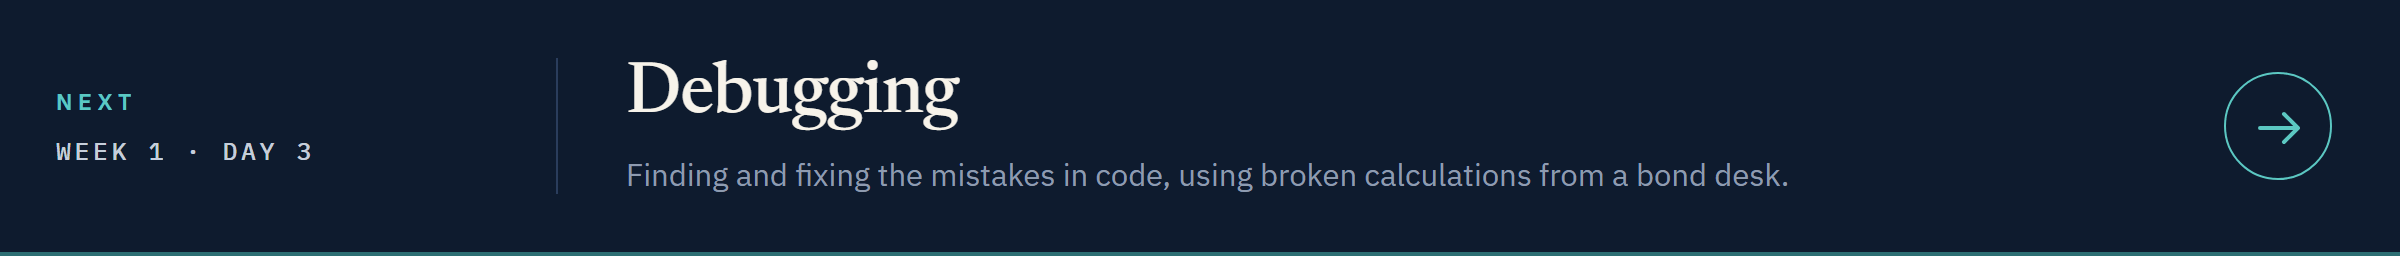](../day3/03_debugging.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week1/day3/03_debugging.ipynb)